In [ ]:
! cd ../Code && make clean && make run

rm -f *.x *.o *.mod *.dat *.bin *.log *~
rm -f -rf 
gfortran -fopenmp -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops -c constants.f90 -o constants.o
gfortran -fopenmp -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops -c controls.f90 -o controls.o
gfortran -fopenmp -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops -c system_parameters.f90 -o system_parameters.o
gfortran -fopenmp -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops -c globals.f90 -o globals.o
gfortran -fopenmp -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops -c losses.f90 -o losses.o
gfortran -fopenmp -ffree-line-length-none -fbackslash -Wno-tabs -fPIC -fmax-errors=1 -O3 -march=native -ffast-math -funroll-loops -c m

# Ajuste de parametros

In [18]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap
import pandas as pd
from scipy.interpolate import interp1d
from matplotlib.patches import Ellipse
import time

In [52]:
import subprocess
def iniciar_pruebas():
    """
    Funcion que modifica el contenido de system_parameters.f90 de forma remota
    """
    # === CONFIGURATION ===
    file_path = '../Code/system_parameters/system_parameters_CenA.f90'        # path to your Fortran file
    line_to_find = '   real(dp), parameter :: rin_0 = 105*R_g'
    new_line = '''   real(dp), parameter :: rin_0 = 135*R_g
    '''  # new content
    
#     line_to_find = '   real(dp), parameter :: zmax_inj = 0.5d3*R_g'  # text in line to search for
#     new_line = '''   real(dp), parameter :: zmax_inj = 0.5d4*R_g          !Jet maximum cell of injection
# '''  # new content
    # === STEP 1: Read and modify the file ===
    with open(file_path, 'r') as file:
        lines = file.readlines()
    for i, line in enumerate(lines):
        if line_to_find in line:
            print(f"Old line: {lines[i].strip()}")
            lines[i] = new_line
            print(f"New line: {lines[i].strip()}")
            break
    else:
        raise ValueError(f"Line containing '{line_to_find}' not found.")
    
    # === STEP 2: Write changes back to the file ===
    with open(file_path, 'w') as file:
        file.writelines(lines)
    
    # ! cd ../Code && make clean && make
    # ! cd ../Code && ./run.x

In [53]:
iniciar_pruebas()

Old line: real(dp), parameter :: rin_0 = 105*R_g
New line: real(dp), parameter :: rin_0 = 135*R_g


# Constantes

In [19]:
incl = 48 * np.pi / 180.0
Nx = 32
f_Ny = 0.15 # Nyquist frequency (< 0.6)
#co = sqrt(8.d0*log(2.d0))       ! difference between sigma and theta!, theta = sigma*co

In [20]:
M_BH = 5.5e7 #             !Black hole mass [Msun]
R_g = 1.477e5*M_BH

#Constants
mJy = 1.0e-26          #mJy to erg cm-2 s-1
eV = 1.602176e-12      # eV to erg


h = 6.6260755e-27 #erg s
k_B = 1.380658e-16
m_e = 9.10938e-28
c = 2.99792458e10
e = 4.8032068e-10
kpc = 3.0856e21  #Kpc a cm
distance = 3.8e3  #Distancia al objeto en kpc
convert = 206265e3/(distance*kpc) # image to angular size (mas)
# flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

fdf = 4.0*np.pi*(distance*kpc)**2  # Flux dilution factor

# Funciones utiles

In [4]:
def safe_log(x):
    return np.where(x > 0, np.log(x), -300)

In [5]:
def get_j_alpha(nu, delta, filename='./../Code/Em_Abs.dat'):
    # Read the data from the file
    data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["frequency", "emisivity", "absorption", "z_value"])
    
    
    # Filter the data for each z_value
    filtered_data = []
    for z in data["z_value"].unique():
        z_data = data[data["z_value"] == z]
        closest_index = (np.abs(z_data["frequency"] - nu*1e9/delta[z-1])).idxmin()
        filtered_data.append(z_data.loc[closest_index, ["frequency", "emisivity", "absorption"]])

    # Combine the filtered data into a DataFrame
    filtered_data = pd.DataFrame(filtered_data)
    return filtered_data['emisivity'], filtered_data['absorption']

In [6]:
def get_z_rz(filename='./../Code/quant_FF.dat',filename2='./../Code/quant_FF_norm.dat'):
    """
    Load and return specific columns from the given file.

    Parameters:
        filename (str): Path to the file containing the data.

    Returns:
        tuple: Arrays of z, B, r_out, r_in, and delta_obs values.
    """
    return np.loadtxt(filename, usecols=(0, 1, 2, 3, 5), unpack=True)

In [7]:
def crossed_length(x, R_in, R_out):
        """
        Calculates the length of the path crossed in the absorbent region
        """
        if abs(x) < abs(R_out) and abs(x) > abs(R_in):
                l = 2.0 * np.sqrt(R_out**2 - x**2)
        elif abs(x) <= abs(R_in):
                l = 2.0 * (np.sqrt(R_out**2 - x**2) - np.sqrt(abs(R_in**2 - x**2)))
        else:
                l = 0.0
        return l

In [8]:
def Omega_beam(theta1, theta2):
    '''Beam solid angle in terms of the theta_HPBW (theta1 x theta2)
    Use the equation here: https://science.nrao.edu/facilities/vla/proposing/TBconv'''
    return np.pi * theta1 * theta2 / (4 * np.log(2))

def brightness_temperature(I, nu_hz):
    """
    Calculate the brightness temperature for a given intensity and frequency.

    Parameters:
    I (float or numpy.ndarray): Specific intensity [mJy].
    nu (float): Frequency [GHz].

    Returns:
    float or numpy.ndarray: Brightness temperature [K].
    """
    nu_hz *= 1e9 # Convert GHz to Hz
    

    return I/Omega_beam(0.0168*1e-3,0.0259*1e-3)#(c**2 * I) / (2 * k_B * nu_hz**2*Omega_beam(np.deg2rad(23 * 1e-3 / 3600),np.deg2rad(45 * 1e-3 / 3600))) #[K]

In [9]:
#Esta interpola las funciones de z
def Intensity_import_interp(x_value, nu, z_value,i):
    '''
    Function that returns the intensity for a given frequency at a given range of z, determined by the length of the input array.
    The function uses the values of absoption and emissivity imported from the function get_j_alpha that are closest to the specified energy
    (given by nu) to calculate the intensity based on the input parameters.
    
    This function interpolates for any given value of z'''

    # Retrieve data
    #This reduces the time cost for running this function multiple times (like in a loop)
    #This data needs to be erased in case some parameters of the model are changed
    if not hasattr(Intensity_import_interp, "_cached_data"):
        z, B, r_out, r_in, delta_obs = get_z_rz()
        delta_obs = np.sqrt(delta_obs)
        j, alpha = get_j_alpha(nu, delta_obs)
        Intensity_import_interp._cached_data = (z, B, r_out, r_in, delta_obs, j, alpha)
    else:
        z, B, r_out, r_in, delta_obs, j, alpha = Intensity_import_interp._cached_data
    j=j.to_numpy()
    alpha=alpha.to_numpy()


    # Interpolations
    I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]
    term_exp_values = [alpha[idx] / delta_obs[idx] for idx in range(len(z))]
    
    valid_indices = ~np.isnan(I_z_values) & ~np.isnan(term_exp_values) # Remove NaN values from I_z_values and term_exp_values
    I_z_values = np.array(I_z_values)[valid_indices]
    term_exp_values = np.array(term_exp_values)[valid_indices]
    z2 = np.array(z)[valid_indices]


    I_z = interp1d(safe_log(z2), safe_log(I_z_values), bounds_error=False, fill_value='extrapolate')
    term_exp = interp1d(safe_log(z2), safe_log(term_exp_values), bounds_error=False, fill_value='extrapolate')
    r_out_interp = interp1d(safe_log(z), safe_log(r_out), bounds_error=False, fill_value='extrapolate')
    r_in_interp = interp1d(safe_log(z), safe_log(r_in), bounds_error=False, fill_value='extrapolate')


    # Compute intensity
    intensity_result = np.zeros(len(x_value))
    r_avg=0.5*(np.exp(r_out_interp(safe_log(z_value)))+np.exp(r_in_interp(safe_log(z_value))))
    tau_avg=crossed_length(r_avg, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
    for j, x in enumerate(x_value):
        tau = crossed_length(x, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
        intensity_result[j] = np.exp(I_z(safe_log(z_value))) * (-np.expm1(-tau)) #(1+tau)# opt thin #[erg/cm^2/s/erg/sr]

    

    return intensity_result, tau_avg #[erg/cm^2/s/Hz/sr]



In [10]:
from numba import njit, prange

@njit(parallel=True) #Parallel running
def compute_F_map_c(x_c, y_c, x_double, y_double, F_map, sigma_x, sigma_y):
    Nx_c = len(x_c)
    Ny_c = len(y_c)
    F_map_c = np.ones((Nx_c, Ny_c))
    w_x = 0.5 / sigma_x ** 2
    w_y = 0.5 / sigma_y ** 2

    #prange corresponds to parallel running
    for i in prange(Nx_c):
        for j in range(Ny_c):
            gaussian = np.exp(-(np.square(x_double - x_c[i]) * w_x + np.square(y_double - y_c[j]) * w_y))
            F_map_c[i, j] = np.sum(F_map * gaussian)
            
        if(i%100==0): print(i,'/',Nx_c) #Progress checking print

    return F_map_c

def Convolve_map(x_map, y_map, F_map, sigma_x, sigma_y):
    #Define the limits of the convolution map
    y_min_c = y_map[0] - 5. * sigma_y
    y_max_c = y_map[-1] + 5. * sigma_y
    x_min_c = x_map[0] - 10. * sigma_x
    x_max_c = x_map[-1] + 10. * sigma_x
    ancho_x = x_max_c - x_min_c
    ancho_y = y_max_c - y_min_c

    Dx_c = f_Ny * sigma_x
    Dy_c = f_Ny * sigma_y 

    Dx_c_rad = np.deg2rad(Dx_c * 1e-3 / 3600)
    Dy_c_rad = np.deg2rad(Dy_c * 1e-3 / 3600)

    # print(F_map.max())

    F_map = F_map * Dx_c_rad * Dy_c_rad #Transform I_nu to S_nu


    # print(F_map.max())
    Nx_c = int(ancho_x*2/ Dx_c)
    Ny_c = int(ancho_y / Dy_c)

    
    x_c = np.linspace(x_min_c, x_max_c, Nx_c)
    y_c = np.linspace(y_min_c, y_max_c, Ny_c)

    x_double = np.tile(x_map[:, None], (1, len(y_map)))
    y_double = np.tile(y_map[None, :], (len(x_map), 1))

    print('Numero de celdas del mapa convolucionado:')
    print(Nx_c, Ny_c)

    print('Dimension of the convolution grid: ' + str(Nx_c) + 'x' + str(Ny_c))
    
        

    F_map_c = compute_F_map_c(x_c, y_c, x_double, y_double, F_map, sigma_x, sigma_y)

    S_pre = np.sum(F_map)
    A_beam = 2 * np.pi * sigma_x * sigma_y
    A_cell = Dx_c * Dy_c
    mJy_beam = A_cell / A_beam
    S_post = np.sum(F_map_c) * mJy_beam

    print('Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')
    print('Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
    print('post/pre = ' + str(S_post / S_pre))

    return x_c, y_c, F_map_c


# Carga de datos

58.929394186034436 para 5e4
84.41384232614853 para 1e4

In [11]:
z, _, r_out, _, _ = get_z_rz()
z=np.geomspace(z.min(),1e4*R_g,200)



x = np.linspace(-4.565578852254577e16, 4.565578852254577e16, 250) #Create a linspace between +-

##########################  Logspaced X  ##########################################################
# A = 4.565578852254577e16 #r_out.max() for z_max=1e7
# n = 150  # points per side

# positive = np.logspace(np.log10(1), np.log10(A), n)
# negative = -positive[::-1]

# x = np.concatenate((negative, [0], positive))


x = x[np.abs(x) <= r_out.max()] #Cut the values outside the actual r_out.max() for the given z_max


# Create a meshgrid for plotting
X_m, Z_m = np.meshgrid(x, z)
I = np.zeros((len(z), len(x)))
tau_avg= np.zeros(len(z))
for i, z_value in enumerate(z):
    I[i], tau_avg[i]=Intensity_import_interp(x, 230.0, z_value,i) #[erg/cm^2/s/Hz/sr]

/tmp/ipykernel_51429/1369176478.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["frequency", "emisivity", "absorption", "z_value"])
/tmp/ipykernel_51429/1023422814.py:25: RuntimeWarning: invalid value encountered in scalar divide
  I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]


In [12]:
#This cell can be used to test how to increse the number of points used for the intensity without changing the number of points in the lower region

# z, _, r_out, _, _ = get_z_rz()
# z=np.geomspace(z.min(),1e5*R_g,325) #You can change the upper value and the number of points and check if the number of points in the lower region remain the same

# k=0
# for i in z:
#     if (i<=1e4*R_g):
#         k+=1

# print(k)

In [13]:
# I.max()*1e26 #1.1412694760520245e+22

In [14]:
if hasattr(Intensity_import_interp, "_cached_data"): #This is the correction to Intensity_import_interp saved data. Run this if you rerun the model
    del Intensity_import_interp._cached_data

In [15]:
print("Hora:", time.strftime("%H:%M"))
print('')

FWHM_x, FWHM_y= 0.0168, 0.0259 #FWHM in mas
sigma_x, sigma_y =FWHM_x/(2*np.sqrt(2*np.log(2))), FWHM_y/(2*np.sqrt(2*np.log(2))) 
X_c, Y_c, I_c = Convolve_map(X_m[0]*convert, Z_m.T[0]*np.sin(incl)*convert, I.T*1e26, sigma_x, sigma_y)

print('')
print("Hora:", time.strftime("%H:%M"))

Hora: 13:29

Numero de celdas del mapa convolucionado:
1484 694
Dimension of the convolution grid: 1484x694
0 / 1484
800 / 1484
100 / 1484
900 / 1484
200 / 1484
1000 / 1484
300 / 1484
1100 / 1484
400 / 1484
1200 / 1484
500 / 1484
1300 / 1484
600 / 1484
1400 / 1484
700 / 1484
Pre-conv: S(GHz) = 217.05086866830476 mJy
Post-conv: S(GHz) = 432.9065623821067 mJy
post/pre = 1.9944935721205093

Hora: 13:37


In [16]:
T_brillo=brightness_temperature(I_c, 230.0) #Transforms the convolution in flux to brightness temperature
T_b=T_brillo
T_b.max()/1e9 

np.float64(80.09370407483135)

In [17]:
# Observaciones de EHT para temperatura de brillo en funcion de la altura

obs_data = pd.read_csv('./EHT_OBS(TBvZ).csv') #Brazo superior
obs_z = obs_data.iloc[:, 0].to_numpy()
obs_TB = obs_data.iloc[:, 1].to_numpy()
obs_data2 = pd.read_csv('./EHT_OBS(TBvZ)2.csv') #Brazo inferior
obs_z2 = obs_data2.iloc[:, 0].to_numpy()
obs_TB2 = obs_data2.iloc[:, 1].to_numpy()


In [18]:

# Convertimos T_b a un dataframe
T_b_df = pd.DataFrame(T_b/1e9, index=X_c, columns=Y_c)

#Separamos cada brazo en un dataframe independiente
T_b_df_plus=T_b_df[T_b_df.index > 0] #Promedio con valores de x positivos
T_b_df_minus=T_b_df[T_b_df.index < 0] #Promedio con valores de x positivos

#Tomamos el maximo a cada altura

# T_b_mean_values = T_b_df_plus.mean(axis=0)                    #Toma el valor medio para cada altura
# T_b_mean_values_minus = T_b_df_minus.mean(axis=0)

T_b_mean_values = T_b_df_plus.max(axis=0)
T_b_mean_values_minus = T_b_df_minus.max(axis=0)

# El Grafico

/tmp/ipykernel_11240/3354634572.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs.set_yticklabels(tick_labels)


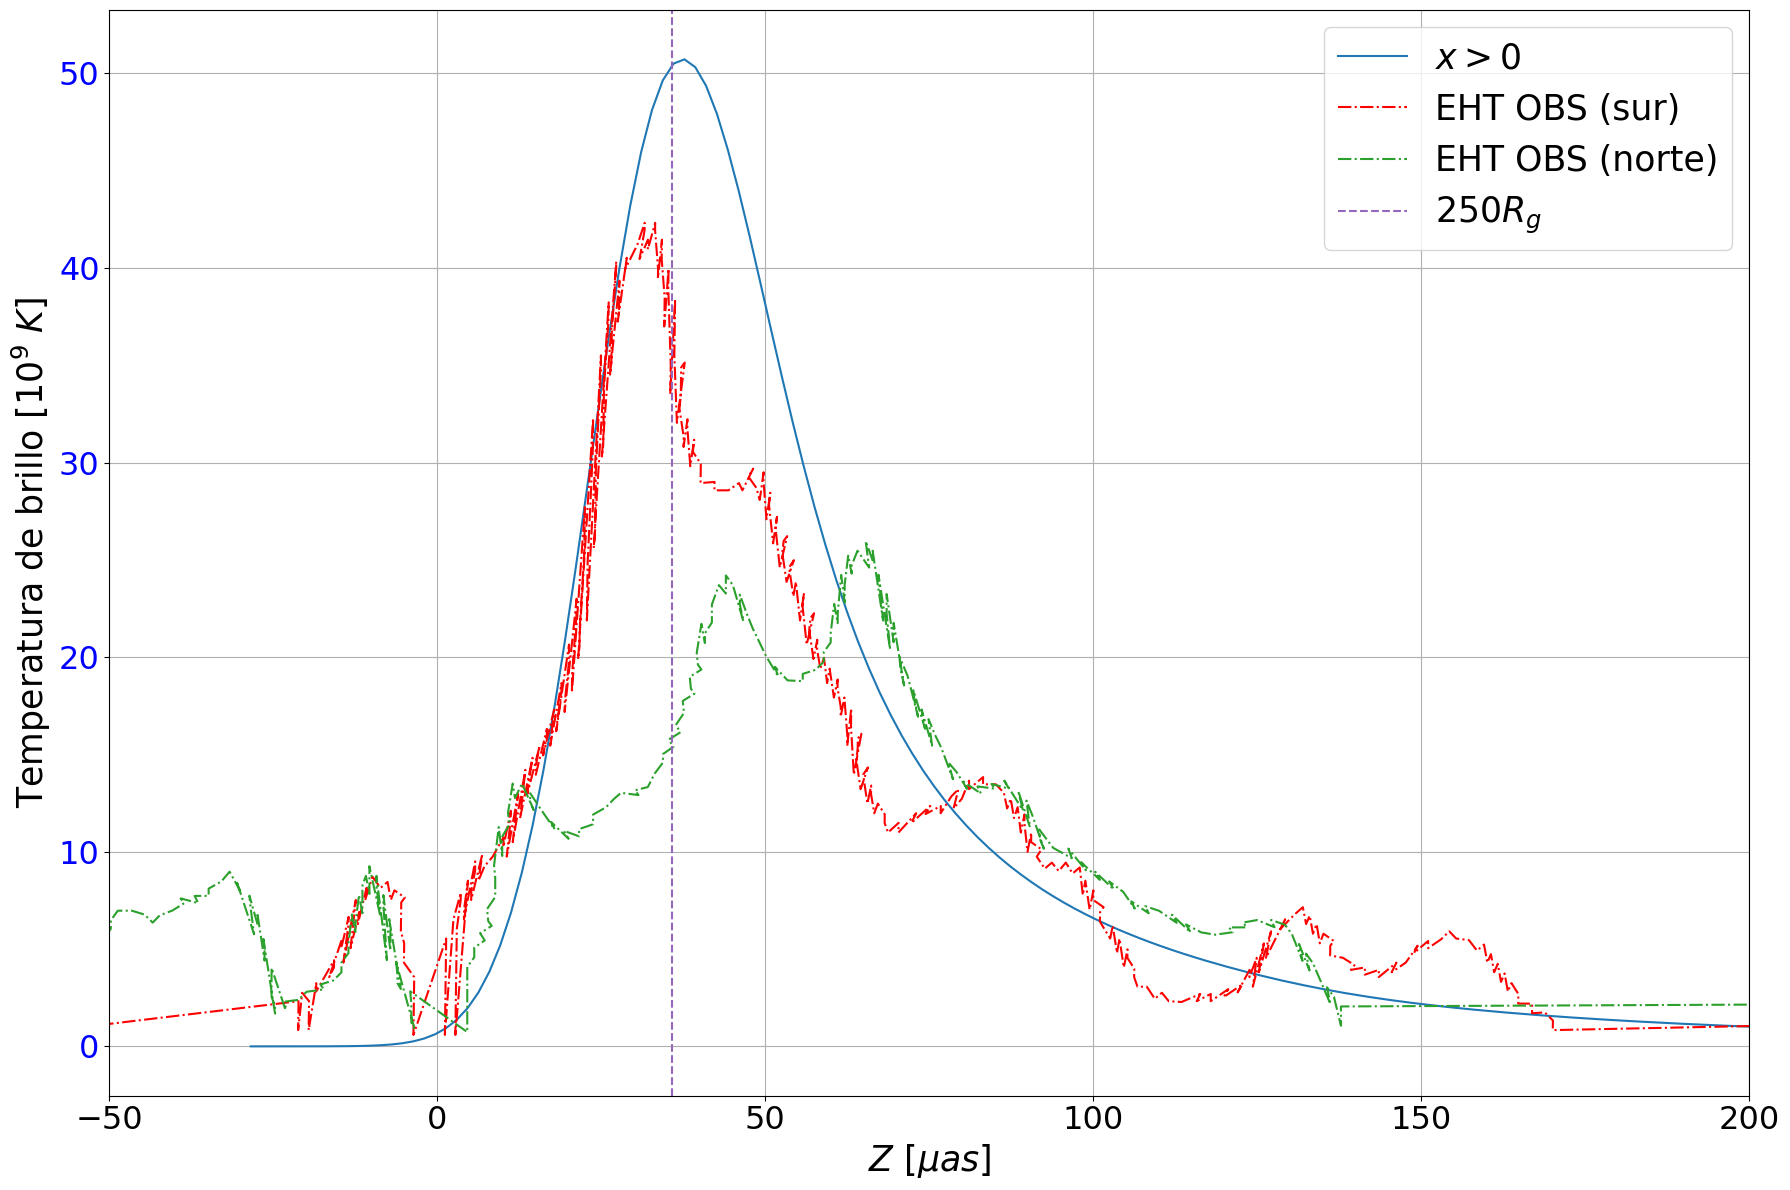

In [20]:
fig, axs = plt.subplots(1, 1, figsize=(18, 12))

# --- T_B vs Z ---
axs.plot(Y_c*1e3, T_b_mean_values, label='$x>0$')
#axs[0].plot(Y_c*1e3, -T_b_mean_values_minus, label='$x<0$')
axs.plot(obs_z, obs_TB, color='red', label='EHT OBS (sur)', linestyle='-.')
axs.plot(obs_z2, -obs_TB2, color='C2', label='EHT OBS (norte)', linestyle='-.')
axs.axvline(x=250*R_g*convert*1e3, color='C4', linestyle='--', label='$250R_g$')
axs.set_xlabel(fr'$Z~[\mu as]$', fontsize=25)
axs.set_ylabel(r'Temperatura de brillo $[10^9~K]$', fontsize=25)
axs.set_xlim(-50, 200)
axs.legend(fontsize=25)
axs.grid()


# Separamos los brazos en azul y naranja
y_ticks = axs.get_yticks()
tick_labels = []
tick_colors = []
plt.tick_params(axis='both', which='major', labelsize=23)
for y in y_ticks:
    tick_labels.append(f"{abs(y):.0f}")
    if y >= 0:
        tick_colors.append('blue')
    else:
        tick_colors.append('orange')
axs.set_yticklabels(tick_labels)
for tick_label, color in zip(axs.get_yticklabels(), tick_colors):
    tick_label.set_color(color)

##############################################################################  Este codigo permite plotear las tres imagenes siguientes en conjunto. Modificar la primera linea para permitir un subplot triple

# # --- Mapa de exposicion ---
# with plt.style.context(('classic')):
#     palette = plt.cm.afmhot
#     ticks = [0.5,1.5,2.5,3.5, 4.5]
#     norm = matplotlib.colors.Normalize(vmin=0.1, vmax=6.5)
#     CS_conv = axs[1].contourf(Y_c, X_c, np.sqrt(T_b/1e9), cmap=palette, norm=norm, levels=np.linspace(0,5.5 , 700))
#     obs_cont = np.array([-1,-0.5,0,0.5,1,2])
#     plot_cont = axs[1].contour(Y_c, X_c, np.sqrt(T_b/1e9), linewidths=1, levels=obs_cont, extend="both", colors=['dimgrey'])
#     el = Ellipse((0.0, 0.075), sigma_y, sigma_x, color='grey')
#     axs[1].add_patch(el)
#     axs[1].set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
#     axs[1].set_ylabel(r"$x~{\rm [mas]}$")
#     axs[1].set_xlim([-0.05, 0.55])
#     axs[1].set_ylim([-0.22, 0.22])
#     axs[1].grid()
#     fig.colorbar(CS_conv, ax=axs[1], ticks=ticks, label=r'$\sqrt{T_b~[10^9~K]}$')

# # --- SED ---
# # Read the data from Flux.dat
# df_flux9 = pd.read_csv('./../Code/Flux_e.dat', sep='\s+', header=0, skiprows=[1])

# def energy_to_freq(E_eV):
#     h = 4.135667696e-15  # eV·s
#     return E_eV / h/1e9

# def freq_to_energy(nu):
#     h = 4.135667696e-15  # eV·s
#     return nu * h*1e9

# axs[2].plot(df_flux9['nu']/1e9, df_flux9['Flujo_Tot']*1e26 , label=r'', linestyle='-', color='red')
# ax_top = axs[2].secondary_xaxis('top', functions=(freq_to_energy, energy_to_freq))
# axs[2].set_xlabel(r'$\nu$ [GHz]')
# axs[2].set_xscale('log')
# axs[2].set_yscale('log')
# ax_top.set_xlabel('Eph [eV]')
# axs[2].set_ylabel('Flujo [mJy]')
# #axs[2].set_title('Total Flux vs $E_{ph}$')
# #axs[2].set_ylim(1e15, 1e30)
# #axs[2].set_xlim(1,1e12)
# axs[2].legend()
# axs[2].grid()



# plt.savefig('Figura1.jpeg', dpi=450)
plt.tight_layout()
plt.show()


### SED

<>:8: SyntaxWarning: invalid escape sequence '\s'


<>:8: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_51429/1729626896.py:8: SyntaxWarning: invalid escape sequence '\s'
  df_flux9 = pd.read_csv('./../Code/Flux_e.dat', sep='\s+', header=0, skiprows=[1])
/tmp/ipykernel_51429/1729626896.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('managua_r', len(flux_columns))


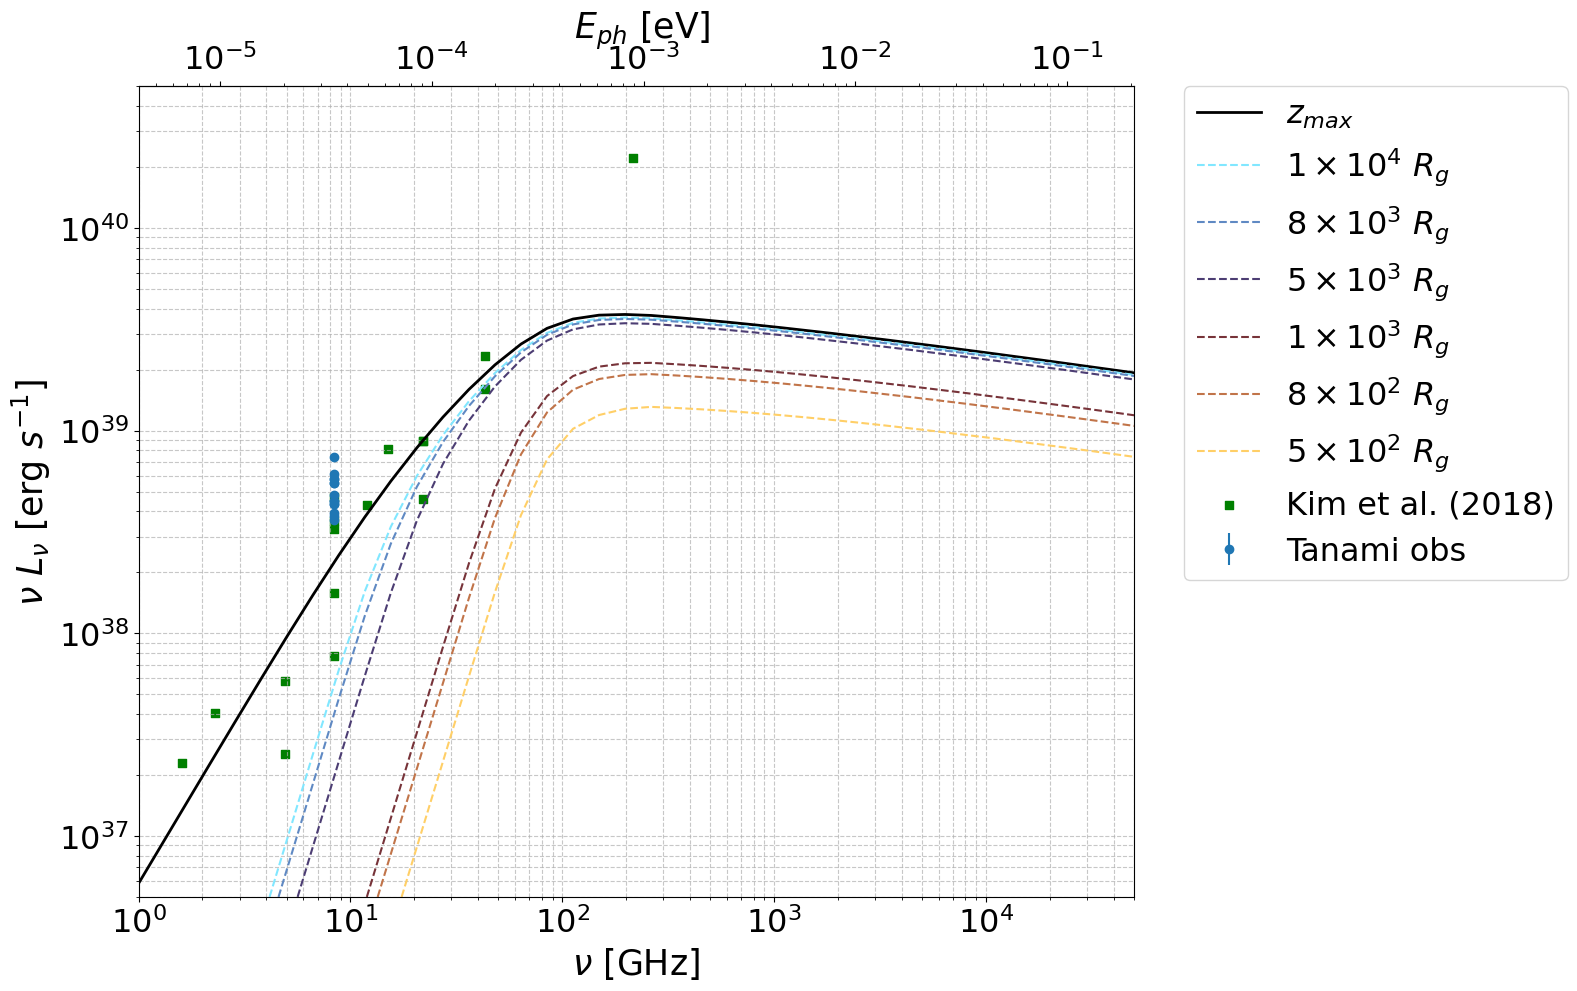

In [31]:
#GRAFICO DE LA SED

from matplotlib import cm

fig, axs = plt.subplots(1, 1, figsize=(16, 10))

# LEEMOS EL ARCHIVO DE SALIDA DEL MODELO
df_flux9 = pd.read_csv('./../Code/Flux_e.dat', sep='\s+', header=0, skiprows=[1])

#Leemos datos observados
KIM_flux = pd.read_csv('Kim(2018)_CENA_OBS.csv', header=0)
# EHT1_flux = pd.read_csv('EHT_226.1918.csv', header=1)
# EHT2_flux = pd.read_csv('EHT_227.0707.csv', header=1)
# EHT3_flux = pd.read_csv('EHT_228.1918.csv', header=1)
EHT4_flux = pd.read_csv('EHT_229.0707.csv', header=1)
tanami_flux = pd.read_csv('TANAMI_cenA_obs.csv', header=0)

#Funciones de transformacion E[eV] a nu[GHz] y viceversa
def energy_to_freq(E_eV):
    h = 4.135667696e-15  # eV·s
    return E_eV / h/1e9

def freq_to_energy(nu):
    h = 4.135667696e-15  # eV·s
    return nu * h * 1e9


# Columnas del plot
flux_columns = [ 'Flujo_6', 'Flujo_5', 'Flujo_4', 'Flujo_3', 'Flujo_2', 'Flujo_1']
labels=[r'$1\times10^4~R_g$',r'$8\times10^3~R_g$',r'$5\times10^3~R_g$',r'$1\times10^3~R_g$',r'$8\times10^2~R_g$',r'$5\times10^2~R_g$']

# Managua colormap
cmap = cm.get_cmap('managua_r', len(flux_columns))
colors = cmap(np.linspace(0, 1, len(flux_columns)))

#Plot de la curva de flujo total 
#====== mJy GHz ================
# axs.plot(
#         df_flux9['nu']/1e9,#Frecuencia en GHz
#         df_flux9['Flujo_Tot']*10**26*df_flux9['nu']/1e9,#Flujo x frecuencia, frecuencia en GHz, flujo en mJy
#         label=r'$z_{max}$',
#         linestyle='-',
#         color='black',
#         lw=2
#     )

#====== erg s-1 ================
axs.plot(
        df_flux9['nu']/1e9,#Frecuencia en GHz
        df_flux9['Flujo_Tot']*fdf*df_flux9['nu'],#Luminosidad x frecuencia, frecuencia en Hz, Eje en erg s-1
        label=r'$z_{max}$',
        linestyle='-',
        color='black',
        lw=2
    )


# Plot de cada curva 1 a 6
#====== mJy GHz ================
# for col, color, label in zip(flux_columns, colors, labels):
#     axs.plot(
#         df_flux9['nu']/1e9,#Frecuencia en GHz
#         df_flux9[col]*10**26*df_flux9['nu']/1e9,#Flujo x frecuencia, frecuencia en Hz, flujo en mJy
#         label=label,
#         linestyle='--',
#         color=color
#     )

#====== erg s-1 ================
for col, color, label in zip(flux_columns, colors, labels):
    axs.plot(
        df_flux9['nu']/1e9,#Frecuencia en GHz
        df_flux9[col]*fdf*df_flux9['nu'],#Luminosidad x frecuencia, frecuencia en Hz, Eje en erg s-1
        label=label,
        linestyle='--',
        color=color
    )


#=============================================================================================    Scatter de datos observados   =======================================================================

# axs.errorbar(tanami_flux['Frequency (Hz)']/1e9,tanami_flux['Flux']*1e3/1e9,yerr=tanami_flux['F Unc High']*1e3/1e9, fmt='o',label='Tanami obs')
axs.errorbar(tanami_flux['Frequency (Hz)']/1e9,tanami_flux['Flux']*1e3*mJy*fdf,yerr=tanami_flux['F Unc High']*mJy*fdf, fmt='o',label='Tanami obs')

# axs.scatter(EHT1_flux['Iamp(Jy)']/EHT1_flux['Iamp(Jy)']*226.1918,EHT1_flux['Iamp(Jy)']*1e3*226.1918,label='EHT obs')
# axs.scatter(EHT2_flux['Iamp(Jy)']/EHT2_flux['Iamp(Jy)']*227.0707,EHT2_flux['Iamp(Jy)']*1e3*227.0707,label='EHT2 obs')
# axs.scatter(EHT3_flux['Iamp(Jy)']/EHT3_flux['Iamp(Jy)']*228.1918,EHT3_flux['Iamp(Jy)']*1e3*228.1918,label='EHT3 obs')
# axs.scatter(EHT4_flux['Iamp(Jy)']/EHT4_flux['Iamp(Jy)']*229.0707,EHT4_flux['Iamp(Jy)']*1e3*229.0707,label='EHT obs', color='black')


axs.scatter(KIM_flux[' Frequency(GHz)'],KIM_flux[' FluxDensity(Jy)']*1e3*mJy*fdf*(KIM_flux[' Frequency(GHz)']*1e9),label='Kim et al. (2018)', color='green', marker='s')
#=======================================================================================================================================================================================================

# Eje superior de E[eV]

ax_top = axs.secondary_xaxis('top', functions=(freq_to_energy, energy_to_freq))
ax_top.set_xlabel(r'$~E_{ph}$ [eV]', fontsize=25)



#Tamano de los ticks
axs.tick_params(axis='both', which='major', labelsize=23)
ax_top.tick_params(axis='x', which='major', labelsize=23)
axs.tick_params(axis='both', which='minor', labelsize=23)

#Labels de los ejes
axs.set_xlabel(r'$\nu$ [GHz]', fontsize=25)
axs.set_ylabel(r'$\nu$ $L_\nu$ [erg $s^{-1}$]', fontsize=25)

#Tipo de eje
axs.set_xscale('log')
axs.set_yscale('log')

#Limites de ejes
axs.set_ylim(5e36, 5e40)
axs.set_xlim(1e0, 5e4)

#Legenda
axs.legend(fontsize=23, loc='upper left', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
#Grid
axs.grid(True, which='both', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(f'Gaussian_Convolved_Map(0).pdf', dpi=450, bbox_inches='tight')
plt.show()

# Done

In [19]:
np.sqrt(T_b.max()/1e9)

np.float64(14.20657173172746)

In [23]:
with plt.style.context(('classic')):
    fig, axs = plt.subplots(1, 1, figsize=(18, 10))
    # axs.set_aspect('equal', adjustable='box')
    #Paleta de la colorbar
    palette = plt.cm.afmhot
    
    #Ticks de la colorbar
    ticks = [0.5,5,10,15]

    #Normalizacion de la colorbar
    norm = matplotlib.colors.Normalize(vmin=0.0, vmax=15)

    #PLot
    CS_conv = axs.contourf(Y_c, X_c, np.sqrt(T_b/1e9), cmap=palette, norm=norm, levels=np.linspace(0,15 , 700))

    #Contornos (Isofotas? Isotermas? Isoalgo.)
    a=[0.5,1.5,2,2.5,3,4]
    obs_cont = np.array(a)#[0.75,1.5,3,6,7.5,8])
    plot_cont = axs.contour(Y_c, X_c, np.sqrt(T_b/1e9), linewidths=1, levels=obs_cont, extend="both", colors=['dimgrey'], linestyles='-')

    #Muestra del Haz gaussiano
    el = Ellipse((0.0, 0.075), sigma_y, sigma_x, color='grey')
    axs.add_patch(el)

    #Labels
    axs.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$", fontsize=35)
    axs.set_ylabel(r"$x~{\rm [mas]}$", fontsize=35)


    #Tamaño de los ticks
    axs.tick_params(axis='both', which='major', labelsize=25)

    #Limites
    axs.set_xlim([-0.05, 0.5])
    axs.set_ylim([-0.15, 0.15])

    #Grid
    axs.grid()

    
    plt.tight_layout()
    cbar=fig.colorbar(CS_conv, ax=axs, ticks=ticks)
    cbar.ax.tick_params(labelsize=25) #Tamano de numeros en la colorbar
    cbar.set_label(r'$\sqrt{T_b~[10^9~K]}$', fontsize=35)
    for t in cbar.ax.get_yticklabels():
        t.set_fontsize(22)
    plt.savefig('Mapa_Tb_convolucion2.jpeg', dpi=450, bbox_inches='tight')


### Graficos varios

In [19]:
#Esto permite guardar informacion para realizar graficos de T_b vs Z con diversos parametros en simultaneo

import os
#Esta celda permite guardar los valores de T_b para plotearlos en conjunto
filename = "T_brillo_output(pruebas1B).txt"
mode = "a" if os.path.exists(filename) else "w"

with open(filename, mode) as f:
    if mode == "a":
        f.write("\n")
    np.savetxt(f, T_brillo)

In [20]:
def read_T_brillo_arrays(filename="T_brillo_output.txt"):
    arrays = []
    with open(filename, "r") as f:
        content = f.read()
        blocks = [block for block in content.strip().split('\n\n') if block.strip()]
        for block in blocks:
            arr = np.loadtxt(block.splitlines())
            arrays.append(arr)
    return arrays

T_brillo_arrays = read_T_brillo_arrays("T_brillo_output(pruebas1B).txt")
print(len(T_brillo_arrays))

5


In [73]:
# Y_cs=[] #Para distintos z0 el Y_c resultante de la convolucion tendra distinta longitud. Ojo con eso al momento de plotear pues puede dar problemas si queremos plotear T_b vs Z proyectado (Y_c)
# print(len(Y_cs))
# Y_cs.append(Y_c)

4

1) Radios
    a) 145/150
    b) 120/150
    c) 100/150
    d) 25/150
    e) 0/150
1B) 
   a) 0.1
   b) 0.3
   c) 0.5
   d) 0.7
   e) 0.9
2) z0
   a) 50
   b) 100
   c) 250
   d) 350

3) z_max_inj
   b)1e4
   a)1e3
   c)1e5

4) a_inj
   0.01
   0.5
   1.0
   1.5


In [22]:
T_brillo_1,T_brillo_2,T_brillo_3,T_brillo_4, T_brillo_5 = T_brillo_arrays[:] 

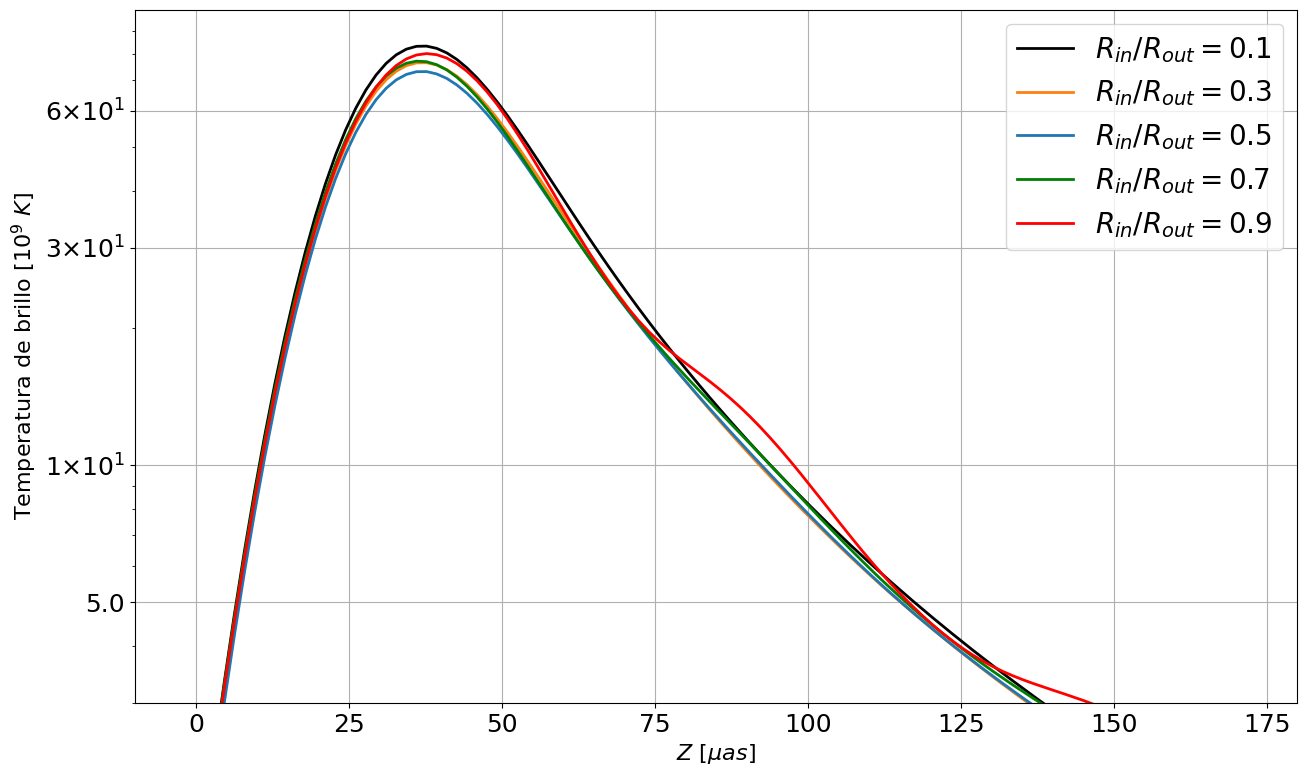

In [25]:
# --- T_B vs Z ---
# Take the highest value along the X_c axis for each Y_c (i.e., max over rows) using for loops
T_b_max_values_list = []


labels = [
    r'$R_{in}/R_{out}=0.1$',
    r'$R_{in}/R_{out}=0.3$',
    r'$R_{in}/R_{out}=0.5$',
    r'$R_{in}/R_{out}=0.7$',
    r'$R_{in}/R_{out}=0.9$'
]
# labels = [
#     r'$\alpha=0.01$',
#     r'$\alpha=0.5$',
#     r'$\alpha=1$',
#     r'$\alpha=1.5$',
# ]
# labels = [
#     r'$z_0=50~R_g$',
#     r'$z_0=100~R_g$',
#     r'$z_0=250~R_g$',
#     r'$z_0=350~R_g$'
#     r'$z_0=250~R_g$, $z_{max, inj}=1e3~R_g$',
#     r'$z_0=250~R_g$, $z_{max, inj}=5e3~R_g$',
#     r'$z_0=250~R_g$, $z_{max, inj}=5e4~R_g$'
# ] 


colorlist =  [
    'black', '#ff7f0e', 'C0', "green",  'red', '#8c564b', '#7f7f7f', '#bcbd22', '#17becf',
    '#aec7e8', '#ffbb78', '#98df8a'
]


T_brillo_list = [T_brillo_1,T_brillo_2,T_brillo_3,T_brillo_4,T_brillo_5]
linestyles = ['-','-', '-', '-','-','--','-.', ':',':']
# colorlist = [colorlist[0],colorlist[3], colorlist[4], colorlist[5]]
# Y_cs=[Y_cs[1],Y_cs[0],Y_cs[2]]


plt.figure(figsize=(15, 9))


for i, T_brillo in enumerate(T_brillo_list):
    T_b_df = pd.DataFrame(T_brillo/1e9, columns=Y_c)
    # Use index > len/2 for x > 0 (positive x)
    T_b_df_plus = T_b_df[T_b_df.index > len(T_b_df)/2]
    # Max along x for each Y_c
    T_b_max_values = T_b_df_plus.max(axis=0)
    T_b_max_values_list.append(T_b_max_values)
    plt.semilogy(Y_c*1e3, T_b_max_values, color=colorlist[i], linestyle=linestyles[i], label=labels[i], lw=2)

# plt.plot(obs_z, obs_TB, color='red',linestyle=':', label='EHT OBS (south)')                    #Para la exploracion de parametros la observacion de Cen A no es necesaria.
# plt.plot(obs_z2, -obs_TB2, color='green',linestyle=':', label='EHT OBS (north)')
#plt.plot(Y_c*1e3, -T_b_mean_values_minus, label='$x<0$')


plt.tick_params(axis='both', which='major', labelsize=18)
plt.xlabel(fr'$Z~[\mu as]$', fontsize=16)
plt.ylabel(r'Temperatura de brillo $[10^9~K]$', fontsize=16)
plt.xlim(-10, 180)
plt.ylim(3,1e2)
plt.yticks([5e0,1e1,3e1,6e1],[r'5.0',r'1$\times 10^1$',r'3$\times 10^1$',r'6$\times 10^1$'])
plt.legend(fontsize=20, loc='upper right')
plt.grid()
# plt.xscale('semi')
# plt.yscale('log')


# # Set y-ticks to absolute values and color positive as blue, negative as orange (Permite separar los brazos sin tener el brazo inferior indicado con temperaturas de brillo negativas)
# ax = plt.gca()
# y_ticks = ax.get_yticks()
# tick_labels = []
# tick_colors = []
# for y in y_ticks:
#     tick_labels.append(f"{abs(y):.0f}")
#     if y >= 0:
#         tick_colors.append('blue')
#     else:
#         tick_colors.append('orange')
# ax.set_yticklabels(tick_labels)
# for tick_label, color in zip(ax.get_yticklabels(), tick_colors):
#     tick_label.set_color(color)


plt.savefig('Tb_vs_Z_(prueba1).jpeg', dpi=450)



/tmp/ipykernel_6378/1233925164.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(tick_labels)


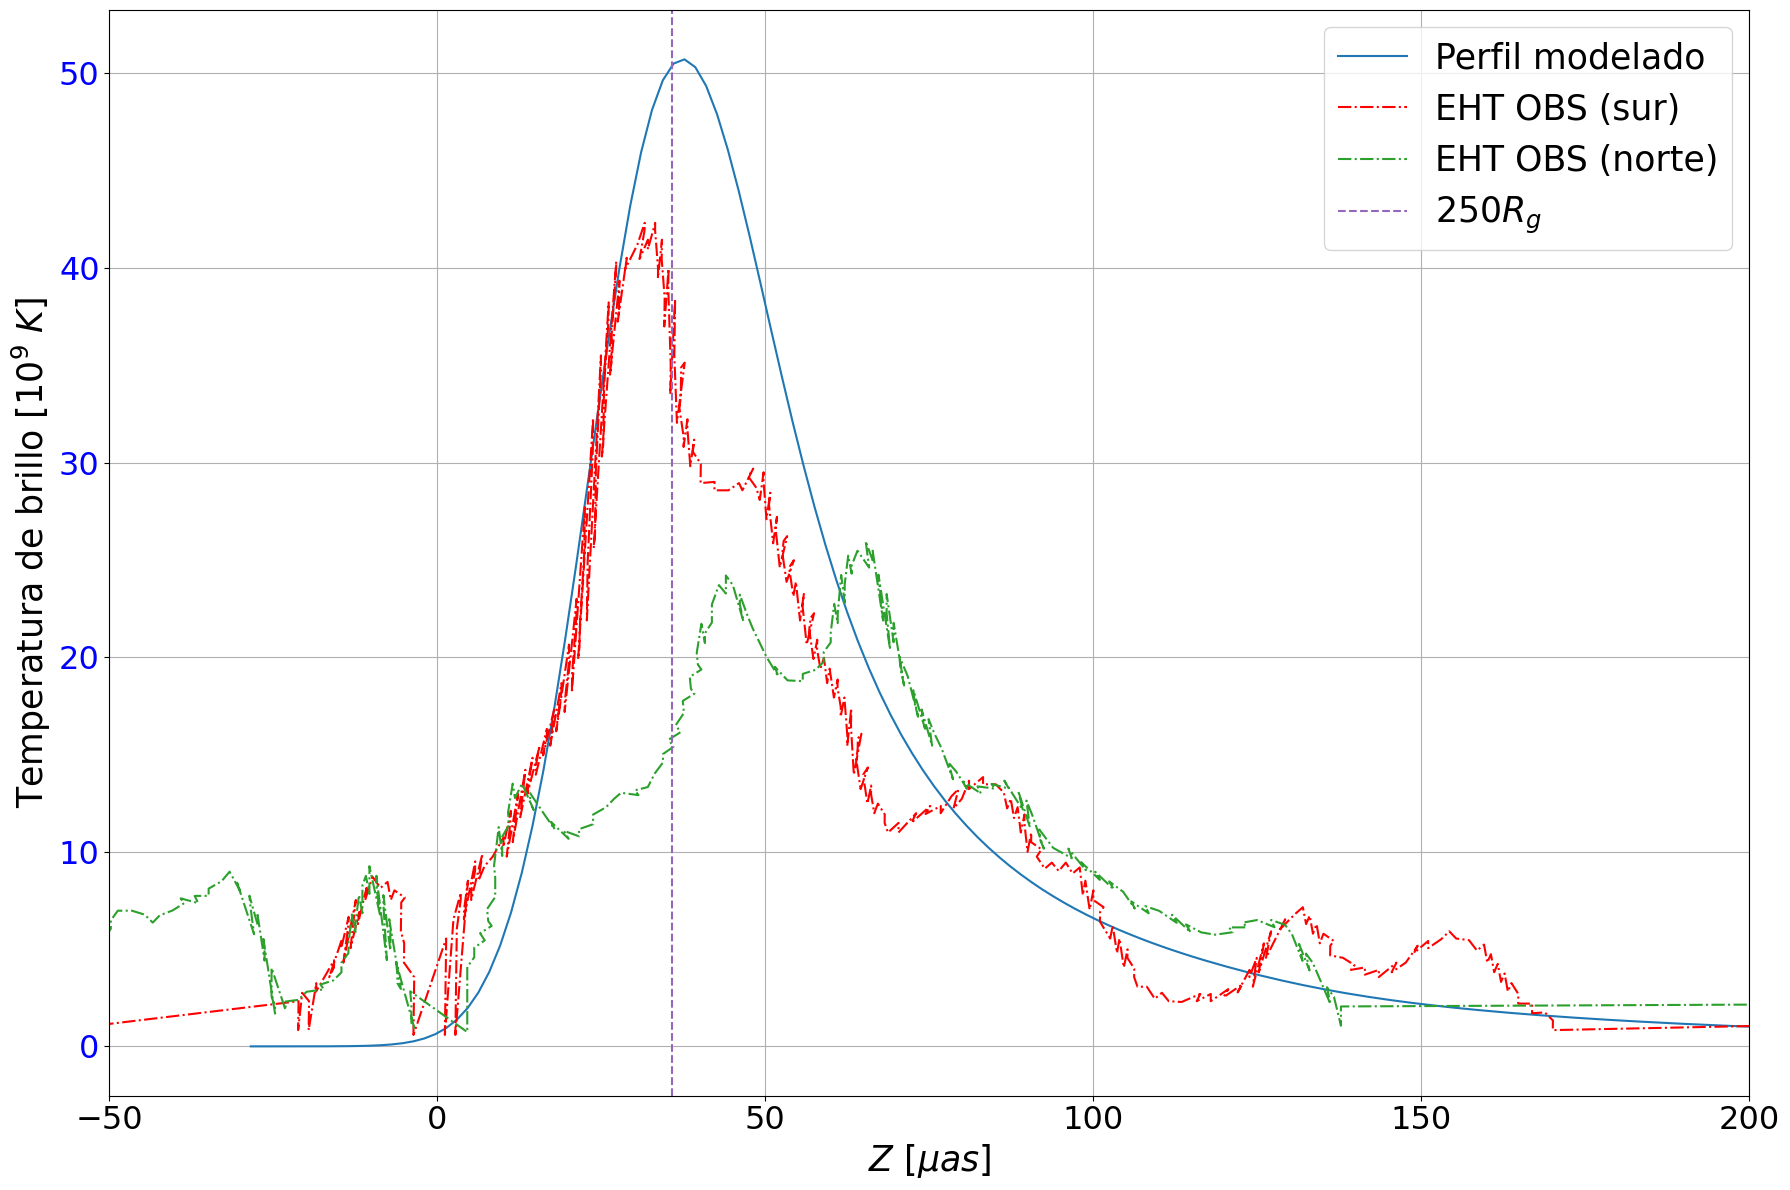

In [37]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(18, 12))

# --- T_B vs Z ---
ax.plot(Y_c*1e3, T_b_mean_values, label='Perfil modelado')
# ax.plot(Y_c*1e3, -T_b_mean_values_minus, label='$x<0$')
ax.plot(obs_z, obs_TB, color='red', label='EHT OBS (sur)', linestyle='-.')
ax.plot(obs_z2, -obs_TB2, color='C2', label='EHT OBS (norte)', linestyle='-.')

# Reference line
ax.axvline(x=250 * R_g * convert * 1e3, color='C4', linestyle='--', label='$250 R_g$')

# Labels and limits
ax.set_xlabel(r'$Z~[\mu as]$', fontsize=25)
ax.set_ylabel(r'Temperatura de brillo $[10^9~K]$', fontsize=25)
ax.set_xlim(-50, 200)

# Grid and legend
ax.grid()
ax.legend(fontsize=25)

# --- Custom tick formatting (blue for +, orange for -) ---
y_ticks = ax.get_yticks()
tick_labels = []
tick_colors = []

plt.tick_params(axis='both', which='major', labelsize=23)

for y in y_ticks:
    tick_labels.append(f"{abs(y):.0f}")   # absolute-value tick labels
    tick_colors.append('blue' if y >= 0 else 'orange')

ax.set_yticklabels(tick_labels)

for tick_label, color in zip(ax.get_yticklabels(), tick_colors):
    tick_label.set_color(color)

plt.tight_layout()
plt.savefig('TvZ.jpeg', dpi=450)
plt.show()


In [2]:
#Leemos dFlux_dz para estudiar el core shift

#Leemos dF_dz
flujo_x_altura = pd.read_csv('./../Code/dFlux_dz.dat', sep='\s+', header=0)

flujo_x_altura=flujo_x_altura.T #Pasa de Frecuencia x Altura a Altura x Frecuencia

flujo_x_altura.columns = flujo_x_altura.iloc[0]      
flujo_x_altura = flujo_x_altura.drop(flujo_x_altura.index[0])  

flujo_x_altura['columna_max'] = flujo_x_altura.idxmax(axis=1)  # Busca en cada fila el valor maximo (flujo) y anota su columna correspondiente (frecuencia) en una nueva columna final


# flujo_x_altura['columna_max'] = flujo_x_altura.drop(columns='nu').idxmax(axis=1)
# flujo_x_altura


<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_52615/233494725.py:4: SyntaxWarning: invalid escape sequence '\s'
  flujo_x_altura = pd.read_csv('./../Code/dFlux_dz.dat', sep='\s+', header=0)


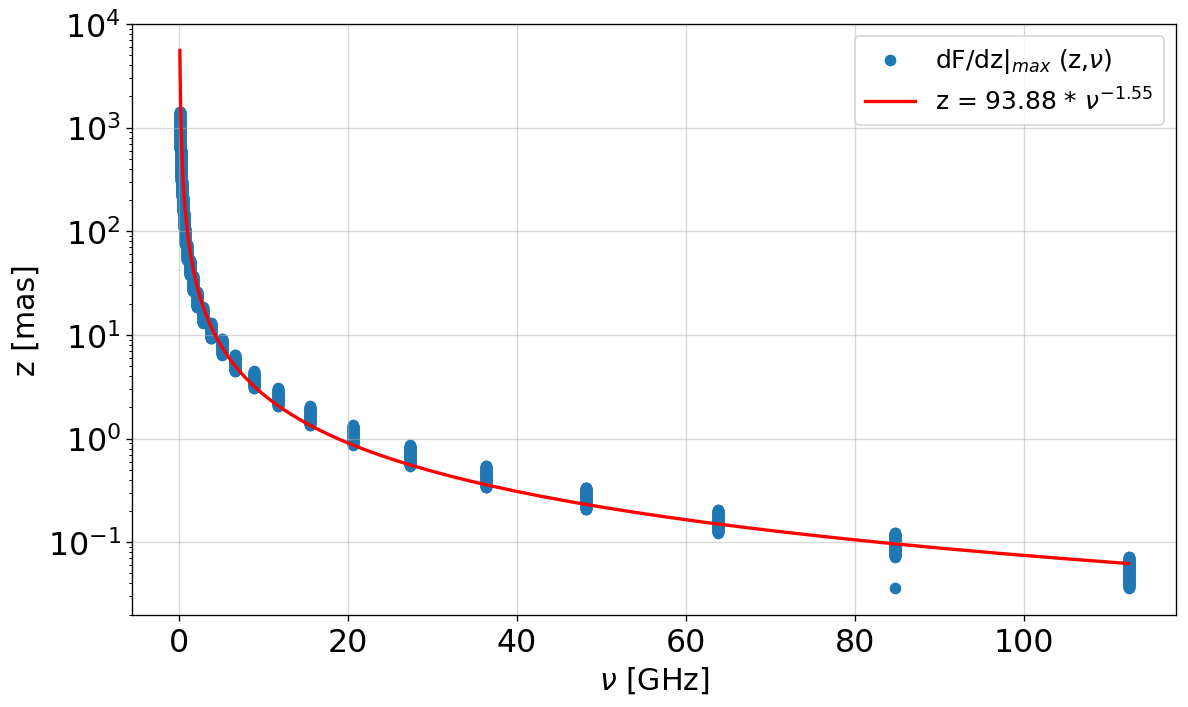

In [17]:
# 🔹 Graficar
ev2ghz=1/1e9/4.135667696e-15

plt.figure(figsize=(10, 6), dpi=120)
#Plot
x_sc = flujo_x_altura['columna_max'][:-1].astype(float) * ev2ghz
y_sc = flujo_x_altura.index.astype(float)[:-1] * convert
plt.scatter(x_sc, y_sc, marker='o', label=r'dF/dz$|_{max}$ (z,$\nu$)')

# Fit power-law (z = A * nu^k) in log-log space
mask = (x_sc > 0) & (y_sc > 0) & np.isfinite(x_sc) & np.isfinite(y_sc)
if mask.sum() >= 2:
    x_fit = x_sc[mask]
    y_fit = y_sc[mask]
    logx = np.log10(x_fit)
    logy = np.log10(y_fit)
    k, logA = np.polyfit(logx, logy, 1)  # logy = k*logx + logA
    A = 10**logA
    x_line = np.logspace(np.log10(x_fit.min()), np.log10(x_fit.max()), 200)
    y_line = (A+40) * x_line**-1.55
    A4=A+40
    plt.plot(x_line, y_line, color='red', lw=2, label=rf'z = {A4:.2f} * $\nu^{{{-1.55}}}$')
    # plt.xscale('log')
else:
    print("No hay suficientes puntos positivos para ajustar una ley de potencias.")


# plt.title(r"Grafico de valores de dF/dz$\Delta z$ maximo en funcion de $z$ y $\nu$")

#Labels
plt.xlabel(r"$\nu$ [GHz]", fontsize=18)
plt.ylabel("z [mas]", fontsize=18)

#Escala
# plt.xscale('log')
plt.yscale('log')

#Limites
# plt.ylim(2e9,2.5e11)

#Tamano de los ticks
plt.tick_params(axis='both', which='major', labelsize=19)

#Grid
plt.grid(True, linestyle='-', alpha=0.5)
#Leyenda
plt.legend(fontsize=15)
plt.tight_layout()
plt.savefig('Core_shift.pdf', dpi=450, bbox_inches='tight')

plt.show()

### T vs Z sin convolucion

In [46]:

z, _, r_out, _, _ = get_z_rz()
z=np.geomspace(z.min(),5e4*R_g,290)


# z_linspace = np.linspace(z.min(), 1e4*R_g, 200)
# dz = z_linspace[1] - z_linspace[0]
# # print(dz)
# # Extensión manteniendo la misma densidad
# z = np.arange(z.min(), z.max() + dz, dz)

# i=0
# j=0
# for value in z:
#     if (1e4*R_g<=value <=1e5*R_g):
#         i=i+1
#     elif (value <=1e4*R_g):
#         j+=1
# print(j,i)

x = np.linspace(-r_out.max(), r_out.max(), 200)


# Create a meshgrid for plotting
X_m, Z_m = np.meshgrid(x, z)
Y_m=Z_m.T[0]*np.sin(incl)*convert
I = np.zeros((len(z), len(x)))
# I_45 = np.zeros((len(z), len(x)))
tau_avg= np.zeros(len(z))
# tau_avg_45= np.zeros(len(z))
for i, z_value in enumerate(z):
    I[i], tau_avg[i]=Intensity_import_interp(x, 230.0, z_value,i) #[erg/cm^2/s/Hz/sr]
    
if hasattr(Intensity_import_interp, "_cached_data"):
    del Intensity_import_interp._cached_data

/tmp/ipykernel_6378/1369176478.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["frequency", "emisivity", "absorption", "z_value"])
/tmp/ipykernel_6378/1023422814.py:25: RuntimeWarning: invalid value encountered in scalar divide
  I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]


In [47]:
#Transforma intensidad a flujo sin pasar por la funcion convolucion

FWHM_x, FWHM_y= 0.0168*0.5, 0.0259*0.5 #FWHM in mas
sigma_x, sigma_y =FWHM_x/(2*np.sqrt(2*np.log(2))), FWHM_y/(2*np.sqrt(2*np.log(2))) 

Dx_c = f_Ny * sigma_x
Dy_c = f_Ny * sigma_y 

Dx_c_rad = np.deg2rad(Dx_c * 1e-3 / 3600)
Dy_c_rad = np.deg2rad(Dy_c * 1e-3 / 3600)

F_map = I.T*1e26 * Dx_c_rad * Dy_c_rad
T_b=brightness_temperature(F_map, 230.0)

In [ ]:
import os
#Esta celda permite guardar los valores de T_b para plotearlos en conjunto
filename = "T_brillo_output(sin_conv).txt"
mode = "a" if os.path.exists(filename) else "w"

with open(filename, mode) as f:
    if mode == "a":
        f.write("\n")
    np.savetxt(f, T_b)

In [41]:
def read_T_brillo_arrays(filename="T_brillo_output.txt"):
    arrays = []
    with open(filename, "r") as f:
        content = f.read()
        blocks = [block for block in content.strip().split('\n\n') if block.strip()]
        for block in blocks:
            arr = np.loadtxt(block.splitlines())
            arrays.append(arr)
    return arrays

T_brillo_arrays = read_T_brillo_arrays("T_brillo_output(sin_conv).txt")
print(len(T_brillo_arrays))

7


In [44]:
T_brillo_1, T_brillo_2, T_brillo_3, T_brillo_4,T_brillo_5,_,_= T_brillo_arrays[:]

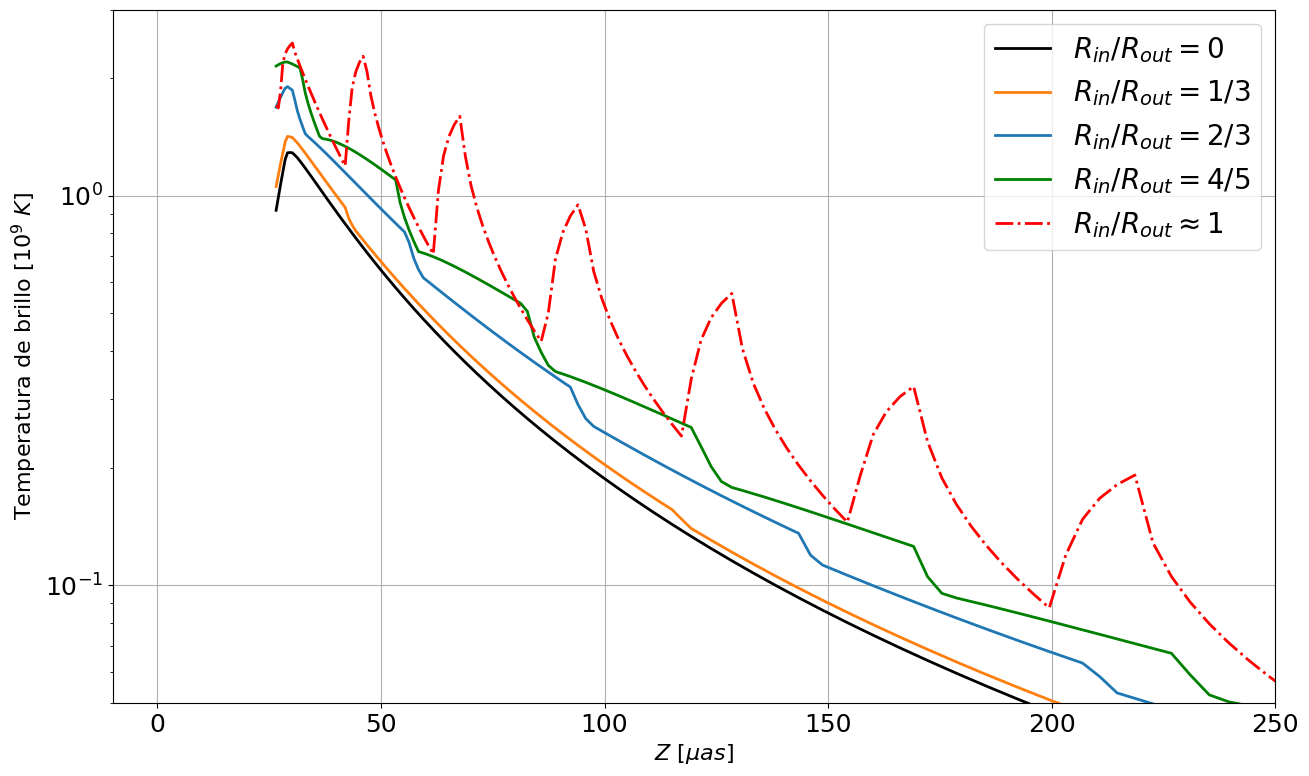

In [48]:
# --- T_B vs Z ---
# Take the highest value along the X_c axis for each Y_c (i.e., max over rows) using for loops
T_b_max_values_list = []
labels = [
    r'$R_{in}/R_{out}=0$',
    r'$R_{in}/R_{out}=1/3$',
    r'$R_{in}/R_{out}=2/3$',
    r'$R_{in}/R_{out}=4/5$',
    r'$R_{in}/R_{out}\approx 1$',
    # r'$R_{in}=105~R_g$',
    # r'$R_{in}=105~R_g$, $\alpha=0.6$',
    # r'$R_{in}=50~R_g$, $\alpha=0.6$',
]
# labels = [
#     r'$\alpha=0.01$',
#     r'$\alpha=0.5$',
#     r'$\alpha=1$',
#     r'$\alpha=1.5$',
# ]
# labels = [
#     r'$z_0=50~R_g$',
#     r'$z_0=100~R_g$',
#     r'$z_0=250~R_g$',
#     r'$z_0=350~R_g$',
#     # r'$z_0=250~R_g$, $z_{max, inj}=1e3~R_g$',
#     # r'$z_0=250~R_g$, $z_{max, inj}=5e3~R_g$',
#     # r'$z_0=250~R_g$, $z_{max, inj}=5e4~R_g$',
# ] 
colorlist =  [
    'black', '#ff7f0e', 'C0', "green",  'red', '#8c564b', '#7f7f7f', '#bcbd22', '#17becf',
    '#aec7e8', '#ffbb78', '#98df8a'
]
T_brillo_list = [T_brillo_1, T_brillo_2, T_brillo_3, T_brillo_4, T_brillo_5]#, T_brillo_6, T_brillo_7, T_brillo_8, T_brillo_9, T_brillo_10, T_brillo_11, T_brillo_12, T_brillo_13]
# labels = [labels[0],labels[1], labels[2], labels[4],labels[3]]
linestyles = ['-','-', '-', '-','-.','--','-.', ':',':']
# colorlist = [colorlist[0],colorlist[3], colorlist[4], colorlist[5]]
# Y_cs=[Y_cs[2],Y_cs[0],Y_cs[1],Y_cs[3]]
plt.figure(figsize=(15, 9))
for i, T_brillo in enumerate(T_brillo_list):
    T_b_df = pd.DataFrame(T_brillo/1e9, columns=Y_m)
    # Use index > len/2 for x > 0 (positive x)
    T_b_df_plus = T_b_df[T_b_df.index > len(T_b_df)/2]
    # Max along x for each Y_c
    T_b_max_values = T_b_df_plus.max(axis=0)
    T_b_max_values_list.append(T_b_max_values)
    plt.semilogy(Y_m*1e3, T_b_max_values, color=colorlist[i], linestyle=linestyles[i], label=labels[i], lw=2)

# plt.plot(obs_z, obs_TB, color='red',linestyle=':', label='EHT OBS (south)')
# plt.plot(obs_z2, -obs_TB2, color='green',linestyle=':', label='EHT OBS (north)')
#plt.plot(Y_c*1e3, -T_b_mean_values_minus, label='$x<0$')
plt.tick_params(axis='both', which='major', labelsize=18)
plt.xlabel(fr'$Z~[\mu as]$', fontsize=16)
plt.ylabel(r'Temperatura de brillo $[10^9~K]$', fontsize=16)
plt.xlim(-10, 250)
plt.ylim(5e-2,3e0)
plt.legend(fontsize=20, loc='upper right')
plt.grid()
# plt.xscale('semi')
# plt.yscale('log')

# # Set y-ticks to absolute values and color positive as blue, negative as orange
# ax = plt.gca()
# y_ticks = ax.get_yticks()
# tick_labels = []
# tick_colors = []
# for y in y_ticks:
#     tick_labels.append(f"{abs(y):.0f}")
#     if y >= 0:
#         tick_colors.append('blue')
#     else:
#         tick_colors.append('orange')
# ax.set_yticklabels(tick_labels)
# for tick_label, color in zip(ax.get_yticklabels(), tick_colors):
#     tick_label.set_color(color)
plt.savefig('Tb_v_Z_SC.jpeg', dpi=450)

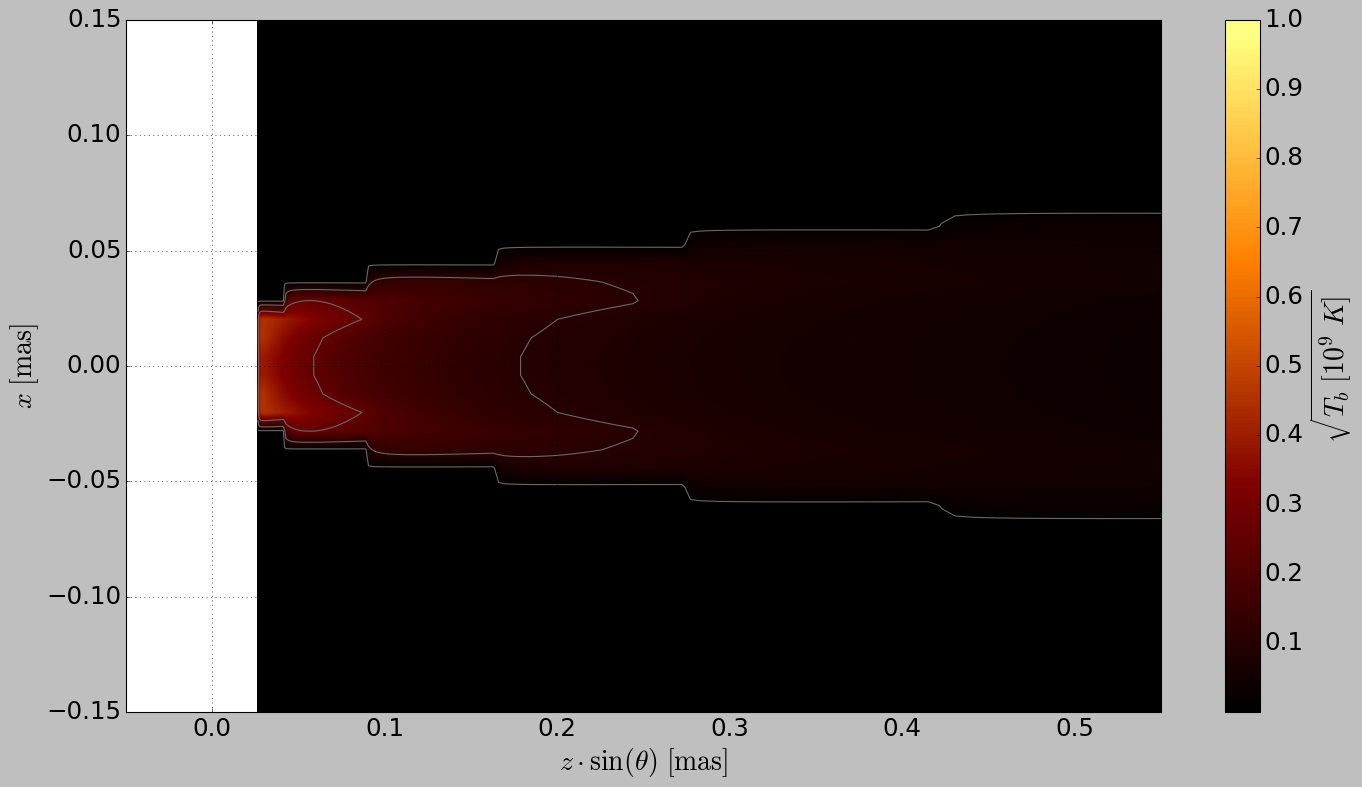

In [49]:


with plt.style.context(('classic')):
    fig, axs = plt.subplots(1, 1, figsize=(18, 10))
    
    #Paleta de la colorbar
    palette = plt.cm.afmhot
    
    #Ticks de la colorbar
    ticks = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1]

    #Normalizacion de la colorbar
    norm = matplotlib.colors.Normalize(vmin=0.001, vmax=1.3)

    #PLot
    CS_conv = axs.contourf(Y_m, X_m[0]*convert, np.sqrt(T_b/1e9), cmap=palette, norm=norm, levels=np.linspace(0,1 , 700))

    #Contornos
    obs_cont = np.array([0.01,0.1,0.25,0.5,1,2])
    plot_cont = axs.contour(Y_m, X_m[0]*convert, np.sqrt(T_b/1e9), linewidths=1, levels=obs_cont, extend="both", colors=['dimgrey'])

    #Haz gaussiano
    # el = Ellipse((0.0, 0.075), sigma_y, sigma_x, color='grey')
    # axs.add_patch(el)

    #Labels
    axs.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$", fontsize=25)
    axs.set_ylabel(r"$x~{\rm [mas]}$", fontsize=25)


    #Tamaño de los ticks
    axs.tick_params(axis='both', which='major', labelsize=22)

    #Limites
    axs.set_xlim([-0.05, 0.55])
    axs.set_ylim([-0.15, 0.15])

    #Grid
    axs.grid(alpha=1)

    
    plt.tight_layout()
    cbar=fig.colorbar(CS_conv, ax=axs, ticks=ticks)
    cbar.ax.tick_params(labelsize=22)
    cbar.set_label(r'$\sqrt{T_b~[10^9~K]}$', fontsize=25)
    for t in cbar.ax.get_yticklabels():
        t.set_fontsize(22)
    plt.savefig('Mapa_Tb.jpeg', dpi=450)